In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.split import split_by_date, VALID_START, TEST_START

sns.set_theme(style="whitegrid")

df = pd.read_parquet("../data/processed/loans_model.parquet")

train, valid, test = split_by_date(df)

In [2]:
summary = pd.DataFrame({
    "loans": [len(train), len(valid), len(test)],
    "first_issue": [s["issue_date"].min().date() for s in (train, valid, test)],
    "last_issue": [s["issue_date"].max().date() for s in (train, valid, test)],
    "default_rate_pct": [round(s["target"].mean() * 100, 2) for s in (train, valid, test)],
}, index=["train", "valid", "test"])

summary["share_pct"] = (summary["loans"] / len(df) * 100).round(1)
summary

,loans,first_issue,last_issue,default_rate_pct,share_pct
train,335558,2007-06-01,2014-12-01,13.06,54.2
valid,120790,2015-01-01,2015-06-01,15.12,19.5
test,162236,2015-07-01,2015-12-01,14.71,26.2


In [3]:
total = len(train) + len(valid) + len(test)
print("All loans accounted for:", total == len(df))

ids_train = set(train["id"])
ids_valid = set(valid["id"])
ids_test = set(test["id"])

print("Train/valid overlap:", len(ids_train & ids_valid))
print("Train/test overlap: ", len(ids_train & ids_test))
print("Valid/test overlap: ", len(ids_valid & ids_test))

All loans accounted for: True
Train/valid overlap: 0
Train/test overlap:  0
Valid/test overlap:  0


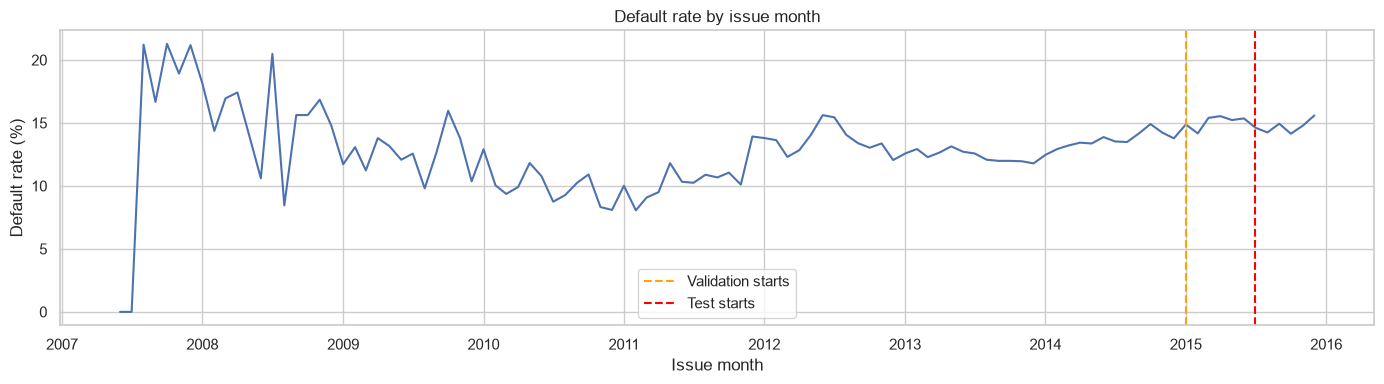

In [4]:
monthly = df.groupby("issue_date")["target"].mean() * 100

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(monthly.index, monthly.values)
ax.axvline(VALID_START, color="orange", linestyle="--", label="Validation starts")
ax.axvline(TEST_START, color="red", linestyle="--", label="Test starts")
ax.set_title("Default rate by issue month")
ax.set_xlabel("Issue month")
ax.set_ylabel("Default rate (%)")
ax.legend()

plt.tight_layout()
plt.savefig("../results/figures/default_rate_by_month_with_split.png", dpi=120)
plt.show()

In [5]:
train.to_parquet("../data/processed/train.parquet", index=False)
valid.to_parquet("../data/processed/valid.parquet", index=False)
test.to_parquet("../data/processed/test.parquet", index=False)
print("Saved.")

Saved.


In [6]:
train.to_parquet("../data/processed/train.parquet", index=False)
valid.to_parquet("../data/processed/valid.parquet", index=False)
test.to_parquet("../data/processed/test.parquet", index=False)
print("Saved.")

Saved.


In [7]:
from src.db import get_engine

split_labels = pd.concat([
    train[["id"]].assign(split="train"),
    valid[["id"]].assign(split="valid"),
    test[["id"]].assign(split="test"),
])

engine = get_engine(fast_executemany=True)
split_labels.to_sql("loan_split", engine, schema="dbo",
                    if_exists="replace", index=False, chunksize=10_000)

print(split_labels["split"].value_counts())

split
train    335558
test     162236
valid    120790
Name: count, dtype: int64
